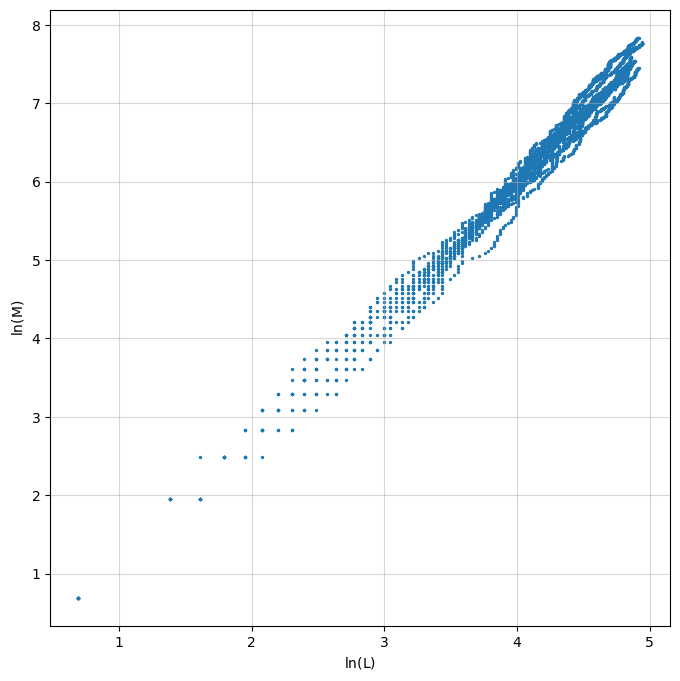

Estimated fractal dimension D_f = 1.727


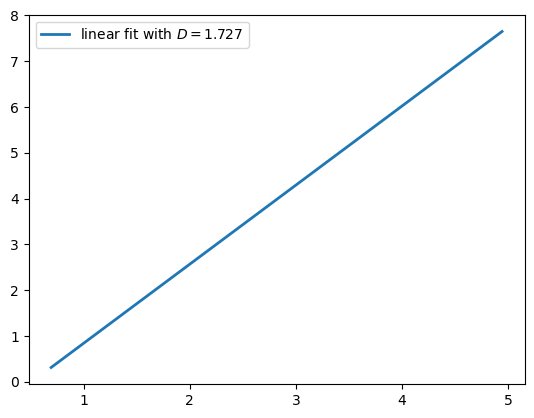

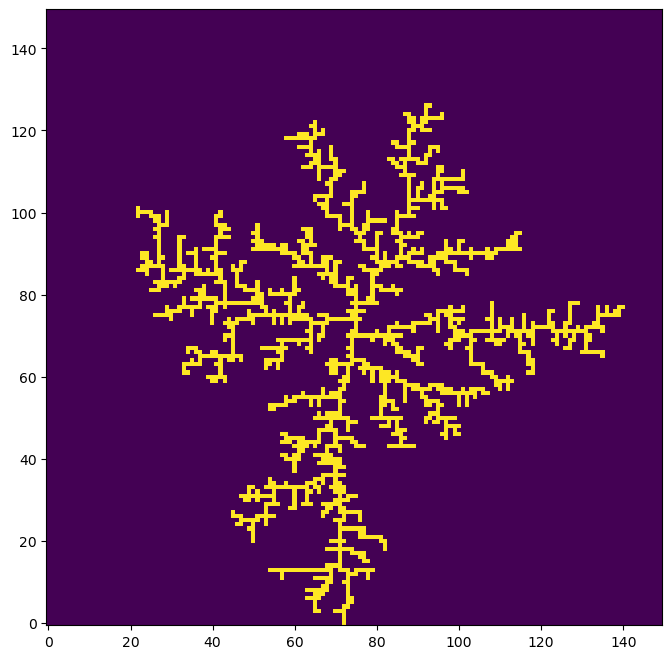

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def simulation(L=40, n=300):
 
    rng = np.random.default_rng()
    occupied = np.zeros((L, L), dtype=bool)

    center = L // 2
    occupied[center, center] = True
    stop = False

    directions = np.array([[1, 0],[-1, 0],[0, 1],[0, -1]])

    for particle in range(n):
        side = rng.integers(4)

        if side == 0:
            x = rng.integers(L)
            y = 0
        elif side == 1:
            x = rng.integers(L)
            y = L - 1
        elif side == 2:
            x = 0
            y = rng.integers(L)
        else:
            x = L - 1
            y = rng.integers(L)

        while True:
            dx, dy = directions[rng.integers(4)]
            x = (x + dx) % L
            y = (y + dy) % L

            touches_cluster = False

            for ddx, ddy in directions:
                nx = (x + ddx) % L
                ny = (y + ddy) % L

                if occupied[nx, ny]:
                    touches_cluster = True
                    break

            if touches_cluster:
                occupied[x, y] = True
                if x == 0 or x == L - 1 or y == 0 or y == L - 1:
                    stop = True
                break
        if particle % 5 == 0:
            x_sites, y_sites = np.where(occupied)
    
            width = np.max(x_sites) - np.min(x_sites)+1
            height = np.max(y_sites) - np.min(y_sites)+1
            
            length = max(width, height)
            M = np.sum(occupied)
            
            arrlength.append(length)
            arrM.append(M)

        if stop:
            break

    return occupied, arrlength, arrM

L = 150
n = 20000
nsimulations = 15
arrM = []
arrlength = []


for nsim in range(nsimulations):
    occupied, arrlength, arrM  = simulation(L=L, n=n)

plt.figure(figsize=(8, 8))
plt.scatter(np.log(arrlength),np.log(arrM),s=2)
plt.xlabel(r"$\ln(\text{L})$")
plt.ylabel(r"$\ln(\text{M})$")
plt.grid(True, which="major", linestyle="-", alpha=0.5)
plt.grid(True, which="minor", linestyle=":", alpha=0.3)
plt.show()

Df, intercept = np.polyfit(np.log(arrlength),np.log(arrM), 1)
print(f"Estimated fractal dimension D_f = {Df:.3f}")
x_fit = np.linspace(np.log(arrlength).min(), np.log(arrlength).max(), 100)
y_fit = Df * x_fit + intercept
plt.plot(
    x_fit,
    y_fit,
    linewidth=2,
    label=fr"linear fit with $D={Df:.3f}$"
)
plt.legend()
plt.figure(figsize=(8, 8))
plt.imshow(occupied.T, origin="lower")
plt.show()